# Image-Only Parkinson's Classification

Transfer-learning experiments using the same image train/test directories.

In [2]:
from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATASET_PATH = ROOT / "data" / "images"

if not DATASET_PATH.exists():
    raise FileNotFoundError("Image dataset not found. Place it under data/images/. See data/images/README.md.")

print("Image dataset:", DATASET_PATH)


Image dataset: <repo>\data\images


In [3]:
import time
import numpy as np
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)

histories_img = {}
results_img = {}

def evaluate_and_store_img(name, model, history, test_generator, train_time):
    test_generator.reset()
    prob = model.predict(test_generator, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    y_true = test_generator.classes

    print(classification_report(y_true, pred, digits=4))
    cm = confusion_matrix(y_true, pred)
    print("Confusion matrix:\n", cm)

    histories_img[name] = history.history
    results_img[name] = {
        "accuracy":  accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall":    recall_score(y_true, pred, zero_division=0),
        "f1":        f1_score(y_true, pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, prob),
        "best_val_acc": max(history.history["val_accuracy"]),
        "final_val_acc": history.history["val_accuracy"][-1],
        "total_params": model.count_params(),
        "train_time_sec": train_time,
        "confusion_matrix": cm,
        "test_prob": prob,
        "y_true": y_true,
    }

## MobileNetV2

In [4]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
MODEL_NAME = "MobileNetV2"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1,
    horizontal_flip=True, fill_mode="nearest"
)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    str(DATASET_PATH / "training"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    str(DATASET_PATH / "testing"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False
)

base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dense(32, activation="relu")(x)
predictions = Dense(1, activation="sigmoid")(x)
model = Model(inputs=base_model.input, outputs=predictions, name=f"{MODEL_NAME}_image_only")
model.compile(optimizer=Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])

print("The application-specific preprocessing function is applied before inference.")
t0 = time.time()
history = model.fit(
    train_generator, epochs=20, validation_data=test_generator,
    verbose=1
)
train_time = time.time() - t0

evaluate_and_store_img(MODEL_NAME, model, history, test_generator, train_time)


Found 72 images belonging to 2 classes.
Found 30 images belonging to 2 classes.
The application-specific preprocessing function is applied before inference.
Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 703ms/step - accuracy: 0.5000 - loss: 1.1841 - val_accuracy: 0.5000 - val_loss: 1.1665
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 304ms/step - accuracy: 0.5000 - loss: 1.0107 - val_accuracy: 0.5000 - val_loss: 1.0059
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step - accuracy: 0.5556 - loss: 0.9152 - val_accuracy: 0.5000 - val_loss: 0.8937
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 431ms/step - accuracy: 0.5417 - loss: 0.7808 - val_accuracy: 0.5667 - val_loss: 0.8205
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 338ms/step - accuracy: 0.4306 - loss: 0.8186 - val_accuracy: 0.5333 - val_loss: 0.7708
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 286ms/step - accuracy: 0.5417 - loss: 0.7401 - val_accuracy: 0.5667 - val_loss: 0.7407
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 290ms/step - accuracy: 0.4722 - loss: 0.7365 - 

## VGG16

In [5]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
MODEL_NAME = "VGG16"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1,
    horizontal_flip=True, fill_mode="nearest"
)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    str(DATASET_PATH / "training"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    str(DATASET_PATH / "testing"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False
)

base_model = VGG16(weights="imagenet", include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dense(32, activation="relu")(x)
predictions = Dense(1, activation="sigmoid")(x)
model = Model(inputs=base_model.input, outputs=predictions, name=f"{MODEL_NAME}_image_only")
model.compile(optimizer=Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])

print("The application-specific preprocessing function is applied before inference.")
t0 = time.time()
history = model.fit(
    train_generator, epochs=20, validation_data=test_generator,
    verbose=1
)
train_time = time.time() - t0

evaluate_and_store_img(MODEL_NAME, model, history, test_generator, train_time)

Found 72 images belonging to 2 classes.
Found 30 images belonging to 2 classes.
The application-specific preprocessing function is applied before inference.
Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.4861 - loss: 1.6077 - val_accuracy: 0.5000 - val_loss: 1.1041
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.4861 - loss: 1.6719 - val_accuracy: 0.5333 - val_loss: 0.9317
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.4722 - loss: 1.5197 - val_accuracy: 0.5333 - val_loss: 0.8257
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.4167 - loss: 1.2593 - val_accuracy: 0.5333 - val_loss: 0.7762
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.5139 - loss: 1.0485 - val_accuracy: 0.5000 - val_loss: 0.7773
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.4722 - loss: 1.0721 - val_accuracy: 0.5333 - val_loss: 0.8111
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.5417 - loss: 0.9783 - val_accuracy: 0.6000 -

## EfficientNetV2B0

In [6]:
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
MODEL_NAME = "EfficientNetV2B0"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1,
    horizontal_flip=True, fill_mode="nearest"
)
test_datagen = ImageDataGenerator()

train_generator = train_datagen.flow_from_directory(
    str(DATASET_PATH / "training"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    str(DATASET_PATH / "testing"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False
)

base_model = EfficientNetV2B0(weights="imagenet", include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dense(32, activation="relu")(x)
predictions = Dense(1, activation="sigmoid")(x)
model = Model(inputs=base_model.input, outputs=predictions, name=f"{MODEL_NAME}_image_only")
model.compile(optimizer=Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])

print("This Keras application includes its own input preprocessing; raw 0-255 image values are passed to the model.")
t0 = time.time()
history = model.fit(
    train_generator, epochs=20, validation_data=test_generator,
    verbose=1
)
train_time = time.time() - t0

evaluate_and_store_img(MODEL_NAME, model, history, test_generator, train_time)

Found 72 images belonging to 2 classes.
Found 30 images belonging to 2 classes.
This Keras application includes its own input preprocessing; raw 0-255 image values are passed to the model.
Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.5278 - loss: 0.6979 - val_accuracy: 0.6000 - val_loss: 0.6562
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 315ms/step - accuracy: 0.5833 - loss: 0.6850 - val_accuracy: 0.6667 - val_loss: 0.6519
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 333ms/step - accuracy: 0.6111 - loss: 0.6669 - val_accuracy: 0.7000 - val_loss: 0.6481
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 355ms/step - accuracy: 0.6806 - loss: 0.6436 - val_accuracy: 0.7000 - val_loss: 0.6457
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 471ms/step - accuracy: 0.6528 - loss: 0.6573 - val_accuracy: 0.7667 - val_loss: 0.6429
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 356ms/step - accuracy: 0.6667 - loss: 0.6593 - val_accuracy: 0.7667 - val_loss: 0.6398
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 348ms/step - accura

## VGG19

In [7]:
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
MODEL_NAME = "VGG19"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1,
    horizontal_flip=True, fill_mode="nearest"
)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    str(DATASET_PATH / "training"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    str(DATASET_PATH / "testing"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False
)

base_model = VGG19(weights="imagenet", include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dense(32, activation="relu")(x)
predictions = Dense(1, activation="sigmoid")(x)
model = Model(inputs=base_model.input, outputs=predictions, name=f"{MODEL_NAME}_image_only")
model.compile(optimizer=Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])

print("The application-specific preprocessing function is applied before inference.")
t0 = time.time()
history = model.fit(
    train_generator, epochs=20, validation_data=test_generator,
    verbose=1
)
train_time = time.time() - t0

evaluate_and_store_img(MODEL_NAME, model, history, test_generator, train_time)

Found 72 images belonging to 2 classes.
Found 30 images belonging to 2 classes.
The application-specific preprocessing function is applied before inference.
Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.4583 - loss: 1.2516 - val_accuracy: 0.4667 - val_loss: 1.1299
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.4444 - loss: 1.1731 - val_accuracy: 0.4667 - val_loss: 0.9911
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5694 - loss: 0.9822 - val_accuracy: 0.5333 - val_loss: 0.8667
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.4861 - loss: 1.0406 - val_accuracy: 0.4000 - val_loss: 0.7842
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.4722 - loss: 1.0226 - val_accuracy: 0.5000 - val_loss: 0.7284
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.4861 - loss: 0.9702 - val_accuracy: 0.5667 - val_loss: 0.6949
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.4306 - loss: 1.0857 - val_accuracy: 0.6000 -

## ResNet50V2

In [8]:
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
MODEL_NAME = "ResNet50V2"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1,
    horizontal_flip=True, fill_mode="nearest"
)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    str(DATASET_PATH / "training"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    str(DATASET_PATH / "testing"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False
)

base_model = ResNet50V2(weights="imagenet", include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dense(32, activation="relu")(x)
predictions = Dense(1, activation="sigmoid")(x)
model = Model(inputs=base_model.input, outputs=predictions, name=f"{MODEL_NAME}_image_only")
model.compile(optimizer=Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])

print("The application-specific preprocessing function is applied before inference.")
t0 = time.time()
history = model.fit(
    train_generator, epochs=20, validation_data=test_generator,
    verbose=1
)
train_time = time.time() - t0

evaluate_and_store_img(MODEL_NAME, model, history, test_generator, train_time)

Found 72 images belonging to 2 classes.
Found 30 images belonging to 2 classes.
The application-specific preprocessing function is applied before inference.
Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.5556 - loss: 0.6993 - val_accuracy: 0.7333 - val_loss: 0.5992
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 507ms/step - accuracy: 0.6389 - loss: 0.6341 - val_accuracy: 0.7667 - val_loss: 0.5834
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 715ms/step - accuracy: 0.5139 - loss: 0.7103 - val_accuracy: 0.8333 - val_loss: 0.5678
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 505ms/step - accuracy: 0.5000 - loss: 0.7045 - val_accuracy: 0.8667 - val_loss: 0.5552
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 569ms/step - accuracy: 0.7083 - loss: 0.5990 - val_accuracy: 0.8667 - val_loss: 0.5448
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 714ms/step - accuracy: 0.6250 - loss: 0.6163 - val_accuracy: 0.8667 - val_loss: 0.5362
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 502ms/step - accuracy: 0.5694 - loss: 0.6581 - val_

## Xception

In [9]:
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
MODEL_NAME = "Xception"
IMAGE_SIZE = (299, 299)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1,
    horizontal_flip=True, fill_mode="nearest"
)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    str(DATASET_PATH / "training"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    str(DATASET_PATH / "testing"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False
)

base_model = Xception(weights="imagenet", include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dense(32, activation="relu")(x)
predictions = Dense(1, activation="sigmoid")(x)
model = Model(inputs=base_model.input, outputs=predictions, name=f"{MODEL_NAME}_image_only")
model.compile(optimizer=Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])

print("The application-specific preprocessing function is applied before inference.")
t0 = time.time()
history = model.fit(
    train_generator, epochs=20, validation_data=test_generator,
    verbose=1
)
train_time = time.time() - t0

evaluate_and_store_img(MODEL_NAME, model, history, test_generator, train_time)

Found 72 images belonging to 2 classes.
Found 30 images belonging to 2 classes.
The application-specific preprocessing function is applied before inference.
Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.5278 - loss: 0.6804 - val_accuracy: 0.7667 - val_loss: 0.6647
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.6111 - loss: 0.6740 - val_accuracy: 0.7667 - val_loss: 0.6569
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.5556 - loss: 0.6845 - val_accuracy: 0.8000 - val_loss: 0.6503
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.6111 - loss: 0.6780 - val_accuracy: 0.8333 - val_loss: 0.6424
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.5694 - loss: 0.6697 - val_accuracy: 0.7667 - val_loss: 0.6349
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.6389 - loss: 0.6555 - val_accuracy: 0.8000 - val_loss: 0.6266
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.6389 - loss: 0.6604 - val_accuracy: 0.8000 -

## InceptionResNetV2

In [10]:
from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.applications.inception_resnet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
MODEL_NAME = "InceptionResNetV2"
IMAGE_SIZE = (299, 299)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1,
    horizontal_flip=True, fill_mode="nearest"
)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    str(DATASET_PATH / "training"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    str(DATASET_PATH / "testing"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False
)

base_model = InceptionResNetV2(weights="imagenet", include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dense(32, activation="relu")(x)
predictions = Dense(1, activation="sigmoid")(x)
model = Model(inputs=base_model.input, outputs=predictions, name=f"{MODEL_NAME}_image_only")
model.compile(optimizer=Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])

print("The application-specific preprocessing function is applied before inference.")
t0 = time.time()
history = model.fit(
    train_generator, epochs=20, validation_data=test_generator,
    verbose=1
)
train_time = time.time() - t0

evaluate_and_store_img(MODEL_NAME, model, history, test_generator, train_time)

Found 72 images belonging to 2 classes.
Found 30 images belonging to 2 classes.
The application-specific preprocessing function is applied before inference.
Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 17s 3s/step - accuracy: 0.4306 - loss: 0.7767 - val_accuracy: 0.4667 - val_loss: 0.7109
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.4444 - loss: 0.7355 - val_accuracy: 0.5333 - val_loss: 0.6881
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5278 - loss: 0.7294 - val_accuracy: 0.5667 - val_loss: 0.6748
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5417 - loss: 0.6985 - val_accuracy: 0.6667 - val_loss: 0.6632
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.6389 - loss: 0.6737 - val_accuracy: 0.6667 - val_loss: 0.6518
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5417 - loss: 0.6890 - val_accuracy: 0.7333 - val_loss: 0.6393
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5000 - loss: 0.7020 - val_accuracy: 0.7000 

## ConvNeXtTiny

In [11]:
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
MODEL_NAME = "ConvNeXtTiny"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1,
    horizontal_flip=True, fill_mode="nearest"
)
test_datagen = ImageDataGenerator()

train_generator = train_datagen.flow_from_directory(
    str(DATASET_PATH / "training"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=SEED
)
test_generator = test_datagen.flow_from_directory(
    str(DATASET_PATH / "testing"), target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, class_mode="binary", shuffle=False
)

base_model = ConvNeXtTiny(weights="imagenet", include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
x = Dense(64, activation="relu")(x)
x = Dense(32, activation="relu")(x)
predictions = Dense(1, activation="sigmoid")(x)
model = Model(inputs=base_model.input, outputs=predictions, name=f"{MODEL_NAME}_image_only")
model.compile(optimizer=Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])

print("This Keras application includes its own input preprocessing; raw 0-255 image values are passed to the model.")
t0 = time.time()
history = model.fit(
    train_generator, epochs=20, validation_data=test_generator,
    verbose=1
)
train_time = time.time() - t0

evaluate_and_store_img(MODEL_NAME, model, history, test_generator, train_time)

Found 72 images belonging to 2 classes.
Found 30 images belonging to 2 classes.
This Keras application includes its own input preprocessing; raw 0-255 image values are passed to the model.
Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.5000 - loss: 0.7451 - val_accuracy: 0.5000 - val_loss: 0.7535
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5000 - loss: 0.7249 - val_accuracy: 0.5000 - val_loss: 0.7299
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5417 - loss: 0.7157 - val_accuracy: 0.5000 - val_loss: 0.7118
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5139 - loss: 0.7226 - val_accuracy: 0.5000 - val_loss: 0.6989
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5278 - loss: 0.6906 - val_accuracy: 0.5000 - val_loss: 0.6876
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5556 - loss: 0.6910 - val_accuracy: 0.5333 - val_loss: 0.6799
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.5139 - loss

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_img = pd.DataFrame(results_img).T.drop(columns=["confusion_matrix", "test_prob", "y_true"])
df_img = df_img.astype({c: float for c in df_img.columns})
df_img = df_img.sort_values("f1", ascending=False)
display(df_img.round(4))

,accuracy,precision,recall,f1,roc_auc,best_val_acc,final_val_acc,total_params,train_time_sec
ConvNeXtTiny,0.8667,0.9231,0.8000,0.8571,0.8978,0.8667,0.8667,27871457.0,115.1033
ResNet50V2,0.8333,0.8125,0.8667,0.8387,0.9467,0.8667,0.8333,23698049.0,38.1601
InceptionResNetV2,0.8000,0.8000,0.8000,0.8000,0.9111,0.8667,0.8000,54437217.0,106.0958
EfficientNetV2B0,0.7667,0.7857,0.7333,0.7586,0.8400,0.7667,0.7667,6003409.0,29.7582
MobileNetV2,0.7000,0.6667,0.8000,0.7273,0.7778,0.7000,0.7000,2342081.0,23.6882
Xception,0.6667,0.6471,0.7333,0.6875,0.8711,0.8333,0.6667,20994729.0,77.1627
VGG19,0.6333,0.6111,0.7333,0.6667,0.7511,0.6667,0.6333,20059329.0,97.7969
VGG16,0.6000,1.0000,0.2000,0.3333,0.7644,0.6000,0.6000,14749633.0,79.6315


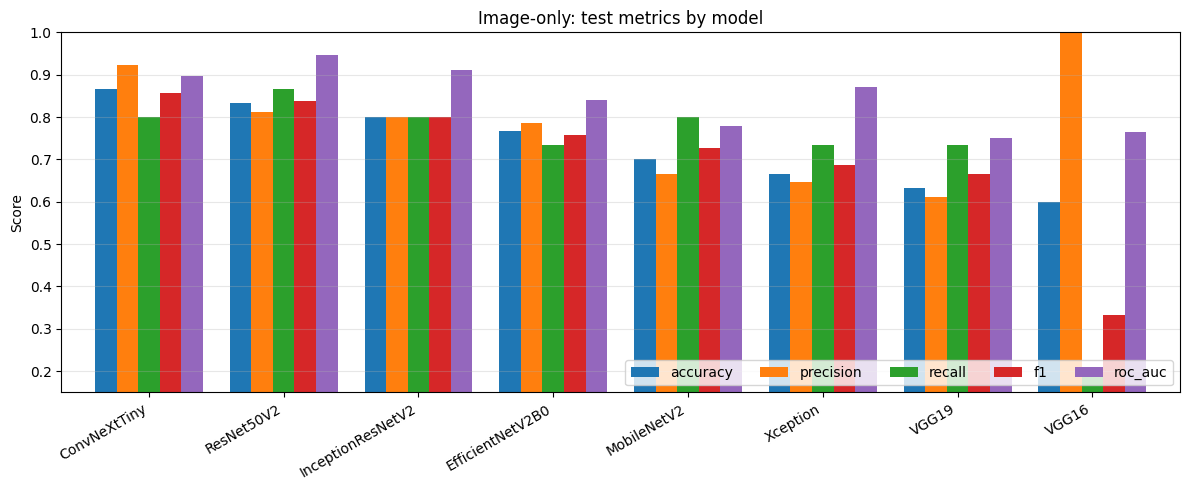

In [16]:
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
ax = df_img[metrics].plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Image-only: test metrics by model")
ax.set_ylabel("Score")
ax.set_ylim(max(0, df_img[metrics].min().min() - 0.05), 1.0)
ax.legend(loc="lower right", ncol=5)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

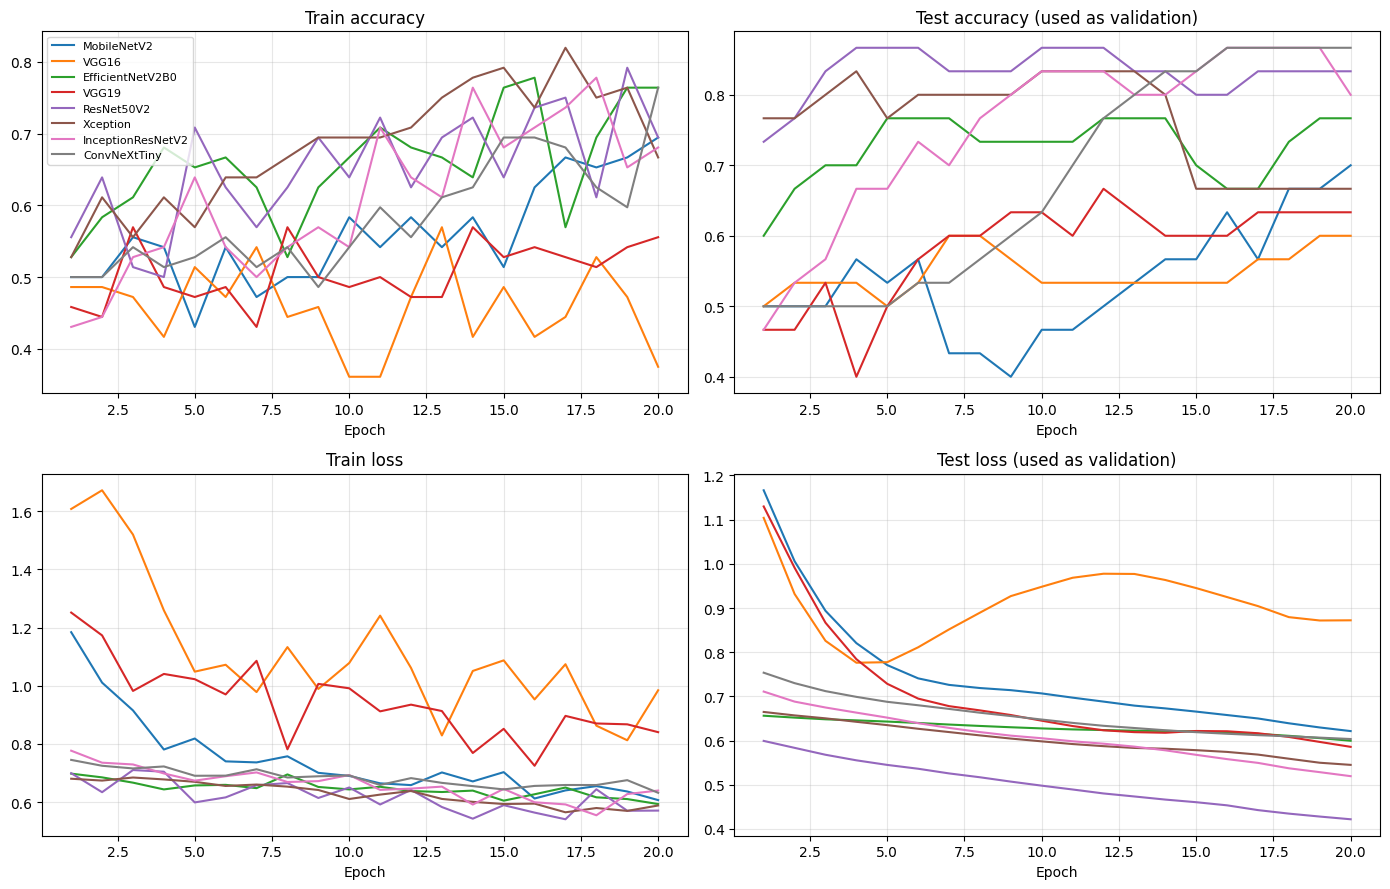

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [("accuracy", "Train accuracy"), ("val_accuracy", "Test accuracy (used as validation)"),
         ("loss", "Train loss"), ("val_loss", "Test loss (used as validation)")]

for ax, (key, title) in zip(axes.ravel(), plots):
    for name, h in histories_img.items():
        ax.plot(range(1, len(h[key]) + 1), h[key], label=name)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

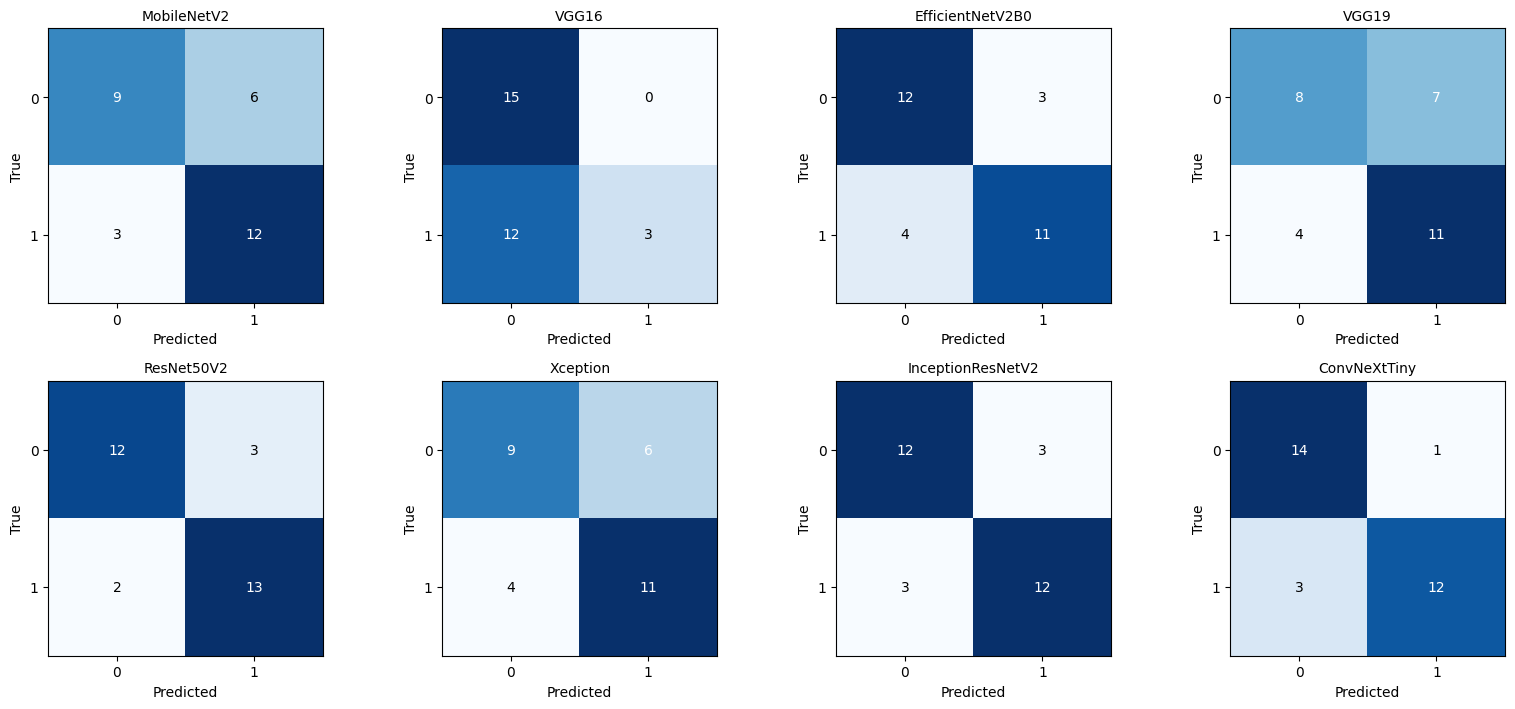

In [19]:
n = len(results_img)
cols = 4
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.6 * rows))
axes = np.array(axes).ravel()

for ax, (name, r) in zip(axes, results_img.items()):
    cm = r["confusion_matrix"]
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

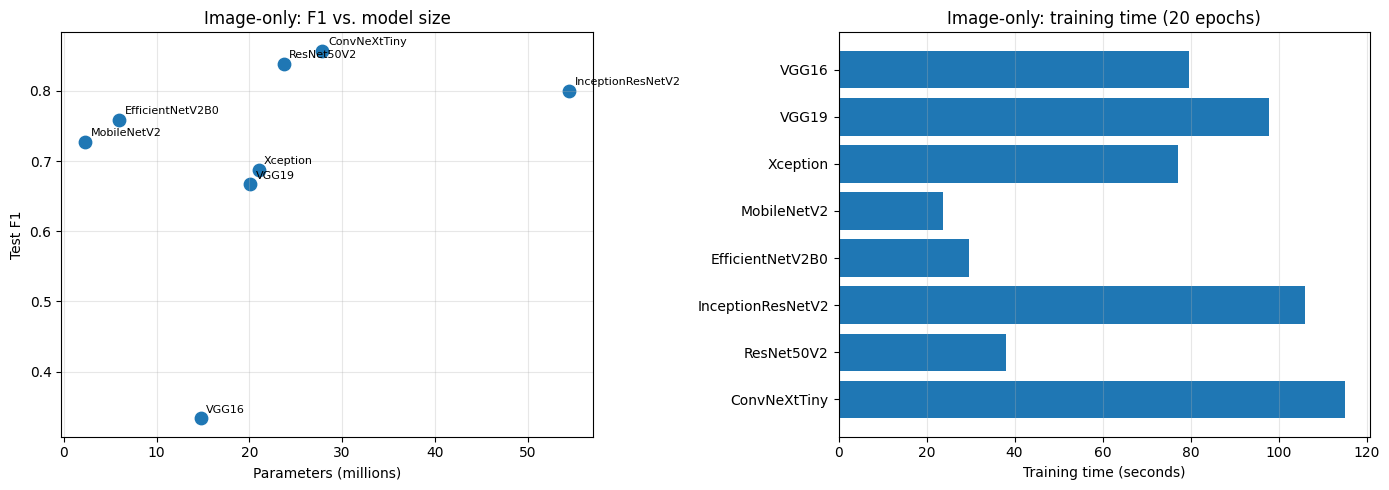

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df_img["total_params"] / 1e6, df_img["f1"], s=80)
for name, row in df_img.iterrows():
    axes[0].annotate(name, (row["total_params"] / 1e6, row["f1"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[0].set_xlabel("Parameters (millions)")
axes[0].set_ylabel("Test F1")
axes[0].set_title("Image-only: F1 vs. model size")
axes[0].grid(alpha=0.3)

axes[1].barh(df_img.index, df_img["train_time_sec"])
axes[1].set_xlabel("Training time (seconds)")
axes[1].set_title("Image-only: training time (20 epochs)")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
import pickle, os

SAVE_DIR = "model_comparison"   # same folder as notebook 1
os.makedirs(SAVE_DIR, exist_ok=True)

with open(os.path.join(SAVE_DIR, "image_only_results.pkl"), "wb") as f:
    pickle.dump({"results_img": results_img, "histories_img": histories_img}, f)

print("Saved to:", os.path.abspath(SAVE_DIR))
print("Models:", list(results_img.keys()))

Saved to: <repo>\notebooks\model_comparison
Models: ['MobileNetV2', 'VGG16', 'EfficientNetV2B0', 'VGG19', 'ResNet50V2', 'Xception', 'InceptionResNetV2', 'ConvNeXtTiny']
